In [1]:
%pip install numpy matplotlib seaborn pylatexenc sympy "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import math
import numpy as np
from IPython.display import display
from qiskit.quantum_info import Statevector
from qiskit import QuantumCircuit, QuantumRegister

from ApproximateEncoder import ApproximateEncoder
from GroverSearch import GroverSearch
from Visualization import state_analysis
from Loader import save_parameters, load_parameters

In [ ]:
num_of_elements = 16
num_of_features = 4

hex_images = [0x0, 0x1, 0x2, 0x3, 0x4, 0x5, 0x6, 0x7, 0x8, 0x9, 0xA, 0xB, 0xC, 0xD, 0xE, 0xF]
dataset = [[(h >> j) & 1 for j in range(num_of_features - 1, -1, -1)] for h in hex_images]

query_index = 11  
query = dataset[query_index]

In [ ]:
dataset

[[0, 0, 0, 0],
 [0, 0, 0, 1],
 [0, 0, 1, 0],
 [0, 0, 1, 1],
 [0, 1, 0, 0],
 [0, 1, 0, 1],
 [0, 1, 1, 0],
 [0, 1, 1, 1],
 [1, 0, 0, 0],
 [1, 0, 0, 1],
 [1, 0, 1, 0],
 [1, 0, 1, 1],
 [1, 1, 0, 0],
 [1, 1, 0, 1],
 [1, 1, 1, 0],
 [1, 1, 1, 1]]

In [ ]:
query_index

11

In [ ]:
query

[1, 0, 1, 1]

# <u>**Part 1: Approximate Encoding Using PQC**</u>

Example for NEQR encoding scheme:

|dataset> = 1/root(N_I*N_D) summation |value> |feature no> |index>
            = |q6 q5 q4 q3 q2 q1 q0>
            = |v> |f1 f0> |i3 i2 i1 i0>

In [ ]:
encoder = ApproximateEncoder()

## <u>**Encoding with NEQR scheme and MMD cost function**</u>

In [ ]:
# A_parameters_neqr_mmd = encoder.generate_encoding(dataset, scheme="NEQR", depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_enocder, learning_rate=learning_rate_dataset_encoder, loss_function_type="MMD")

In [ ]:
# B_parameters_neqr_mmd = encoder.generate_encoding(query, scheme="NEQR", depth=pqc_depth_for_query_encoder, epochs=300, learning_rate=0.005, loss_function_type="MMD")

## <u>**Encoding with NEQR scheme and FIDELITY cost function**</u>

Fidelity ignore global phase but captures relative phase.

Example, 

{a|0> + b|1>} and {-a|0>-b|1>} are physically identical

But for (|0>+|1>)/root(2) and (|0>-|1>)/root(2), fidelity is zero (different states)

In [ ]:
pqc_depth_for_dataset_encoder = 8
pqc_depth_for_query_encoder = 3
epochs_dataset_encoder = 500
learning_rate_dataset_encoder = 0.005

In [ ]:
# Load previously saved A, if available
A_saved_best_fidelity = 0

try:
    A_saved = load_parameters(scheme="NEQR", loss_function_type="FIDELITY")

    A_saved_parameters = A_saved["parameters"]
    A_saved_best_fidelity = A_saved["fidelity"]

    print(f"Loaded saved dataset encoder. Fidelity = {A_saved_best_fidelity:.6f}")

except (ValueError, KeyError, OSError) as e:
    print(f"Could not reuse saved dataset encoder. Train again.")

Loaded saved A. Fidelity = 0.985157



> Preparing dataset target state....

Num of data elements (N_I): 16
Num of features (N_D): 4
Number of index qubits (n_index_q): 4
Number of data qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 7
Total number of states:  128

Amplitude =  0.125

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 64

> Starting training....

Number of parameters = 56

> Using adam optimization....
Epoch 1 - Loss 0.9998562955098885 - Fidelity 0.00014370449011143966
Epoch 2 - Loss 0.9995874253553898 - Fidelity 0.00041257464461014545
Epoch 3 - Loss 0.9991624937291417 - Fidelity 0.0008375062708582886
Epoch 4 - Loss 0.9985746171578269 - Fidelity 0.0014253828421730648
Epoch 5 - Loss 0.9978185672458787 - Fidelity 0.0021814327541213054
Epoch 6 - Loss 0.9968901529248705 - Fidelity 0.0031098470751295556
Epoch 7 - Loss 0.9957861570101352 - Fidelity 0.004213842989864795
Epoch 8 - Loss 0.9945041206920612 - Fidelity 0.005495879307938787
Epoch 9 - Loss 0.9930418053592487 - Fidelity 0.0069581946407513235
Epoch 10 - Loss 0.9913974349824584 - Fidelity 0.008602565017541617
Epoch 11 - Loss 0.9895708234318817 - Fidelity 0.0104291765681183
Epoch 12 - Loss 0.9875636050380645 - Fidelity 0.012436394961935472
Epoch 13 - Loss 0.985379125466432 - Fidelity 0.014620874533567932
Epoch 14

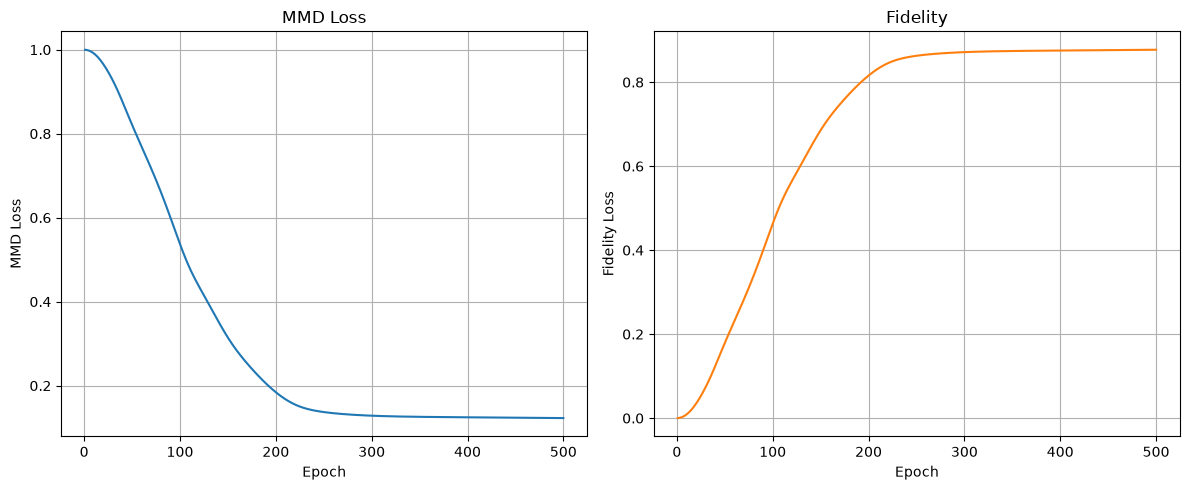


> Training finished.
Number of qubits: 7
Circuit depth (layers): 8
Number of parameters: 56
Best fidelity achieved: 0.87724347


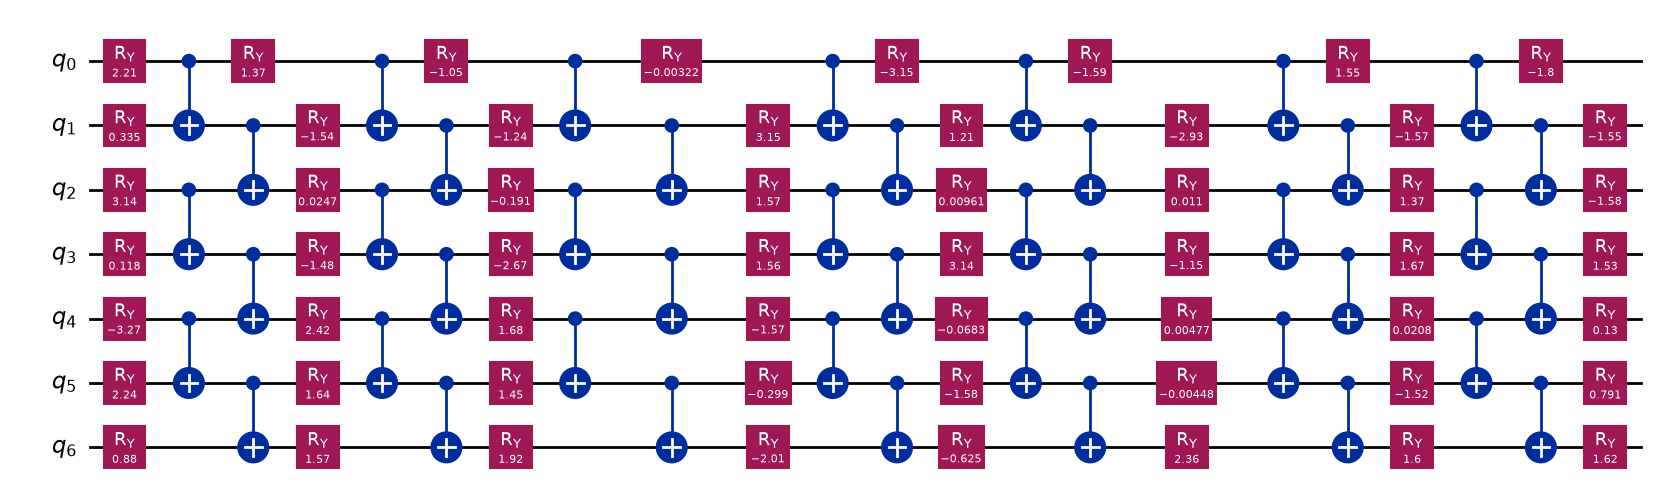


Data =  [[0 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 0 1 1]
 [0 1 0 0]
 [0 1 0 1]
 [0 1 1 0]
 [0 1 1 1]
 [1 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [1 1 0 1]
 [1 1 1 0]
 [1 1 1 1]]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.87724347


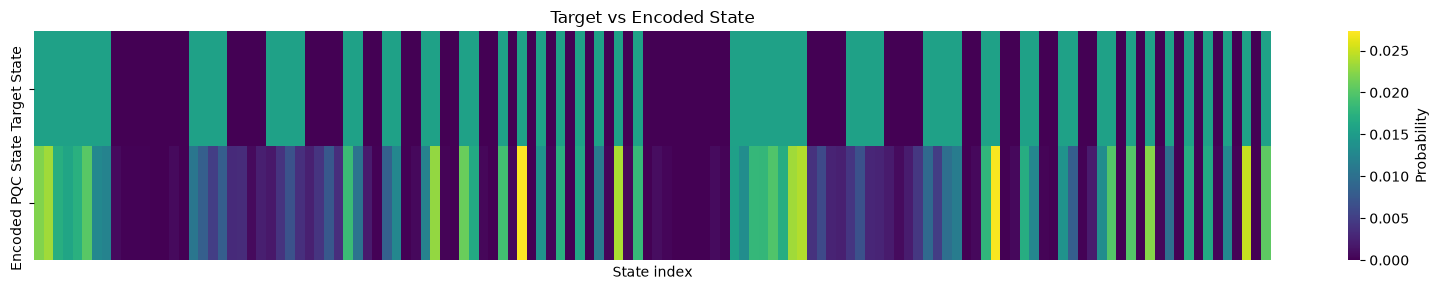

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

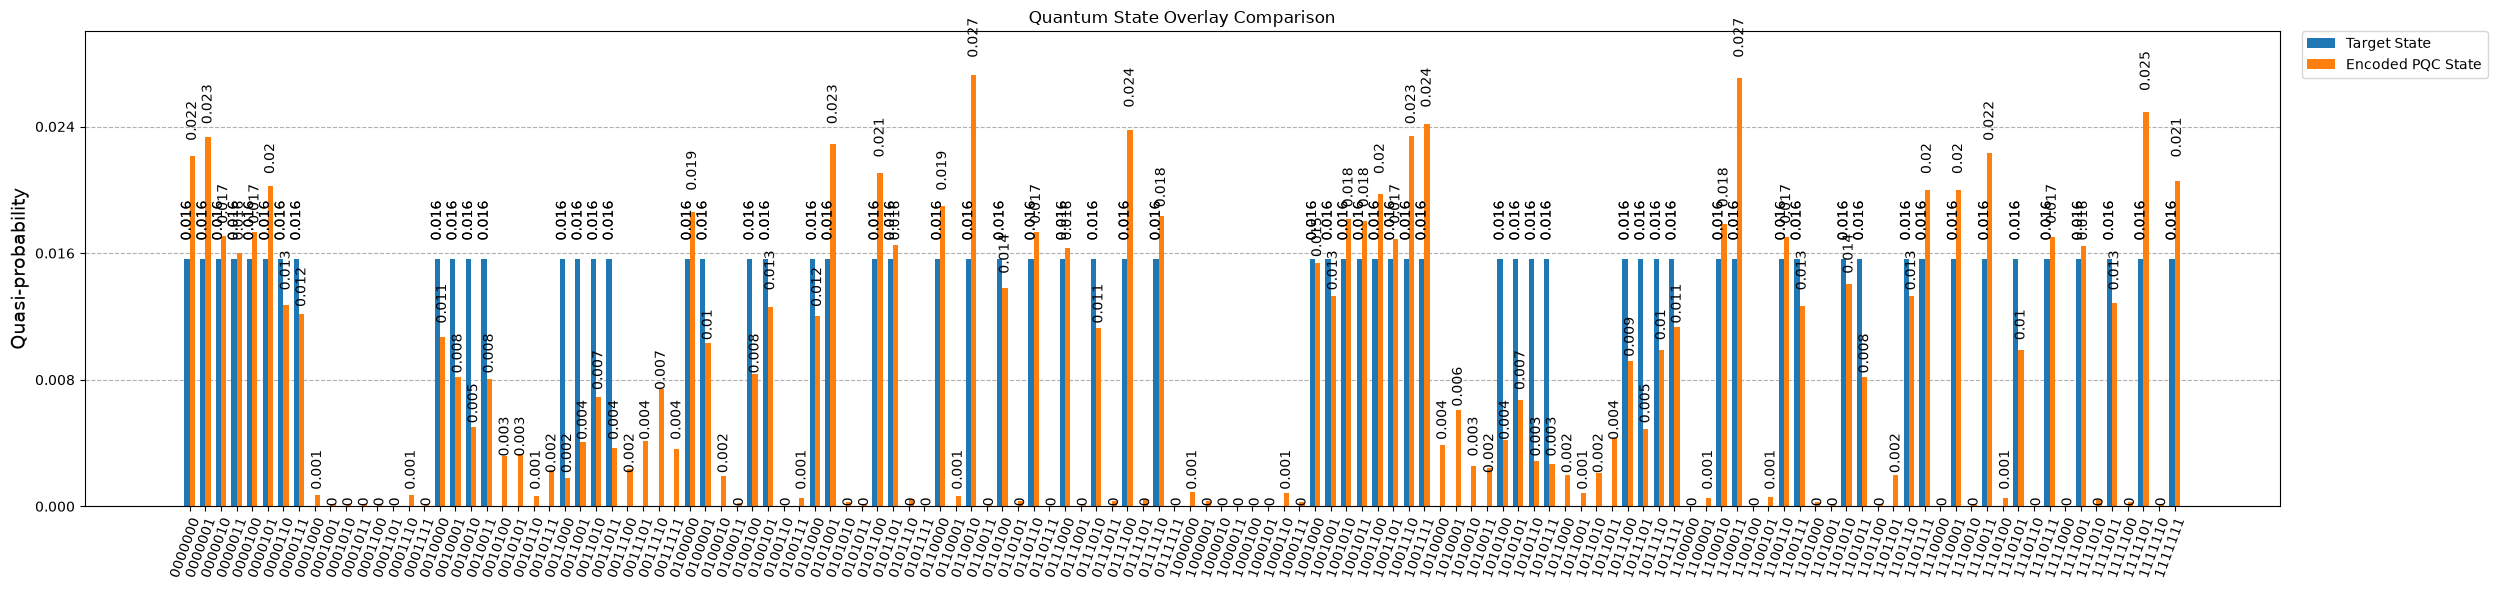


TARGET STATE
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.125                   +0.000                   
0                        1                        +0.125                   +0.000                   
0                        2                        +0.125                   +0.000                   
0                        3                        +0.125                   +0.000                   
1                        0                        +0.125                   +0.000                   
1                        1                        +0.125                   +0.000                   
1                        2                        +0.125                   +0.000                   
1                        3                        +0.000                   +0

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.148810232912073+0j)
|0000001> : (0.1528175204918282+0j)
|0000010> : (0.13068912795524973+0j)
|0000011> : (0.12661353670138573+0j)
|0000100> : (0.13163966143333977+0j)
|0000101> : (0.14226128714781516+0j)
|0000110> : (0.11278040741108904+0j)
|0000111> : (0.11027537579300825+0j)
|0001000> : (-0.02685874921244492+0j)
|0001001> : (-0.011100748982697063+0j)
|0001010> : (0.01309290445649661+0j)
|0001011> : (-0.012729345875892353+0j)
|0001100> : (-0.007401878301207264+0j)
|0001101> : (0.005455697387470002+0j)
|0001110> : (0.02731272989136348+0j)
|0001111> : (0.0074303447939270285+0j)
|0010000> : (0.10340345918962107+0j)
|0010001> : (0.09034563275198197+0j)
|0010010> : (0.0706126619853581+0j)
|0010011> : (0.08955617956244892+0j)
|0010100> : (0.056607579028076505+0j)
|0010101> : (0.05764018411097157+0j)
|0010110> : (0.02588651488752697+0j)
|0010111> : (0.04817603343076083+0j)
|0011000> : (0.04208878279004878+0j)
|0011001> : (0.06354127992283266+0j)
|

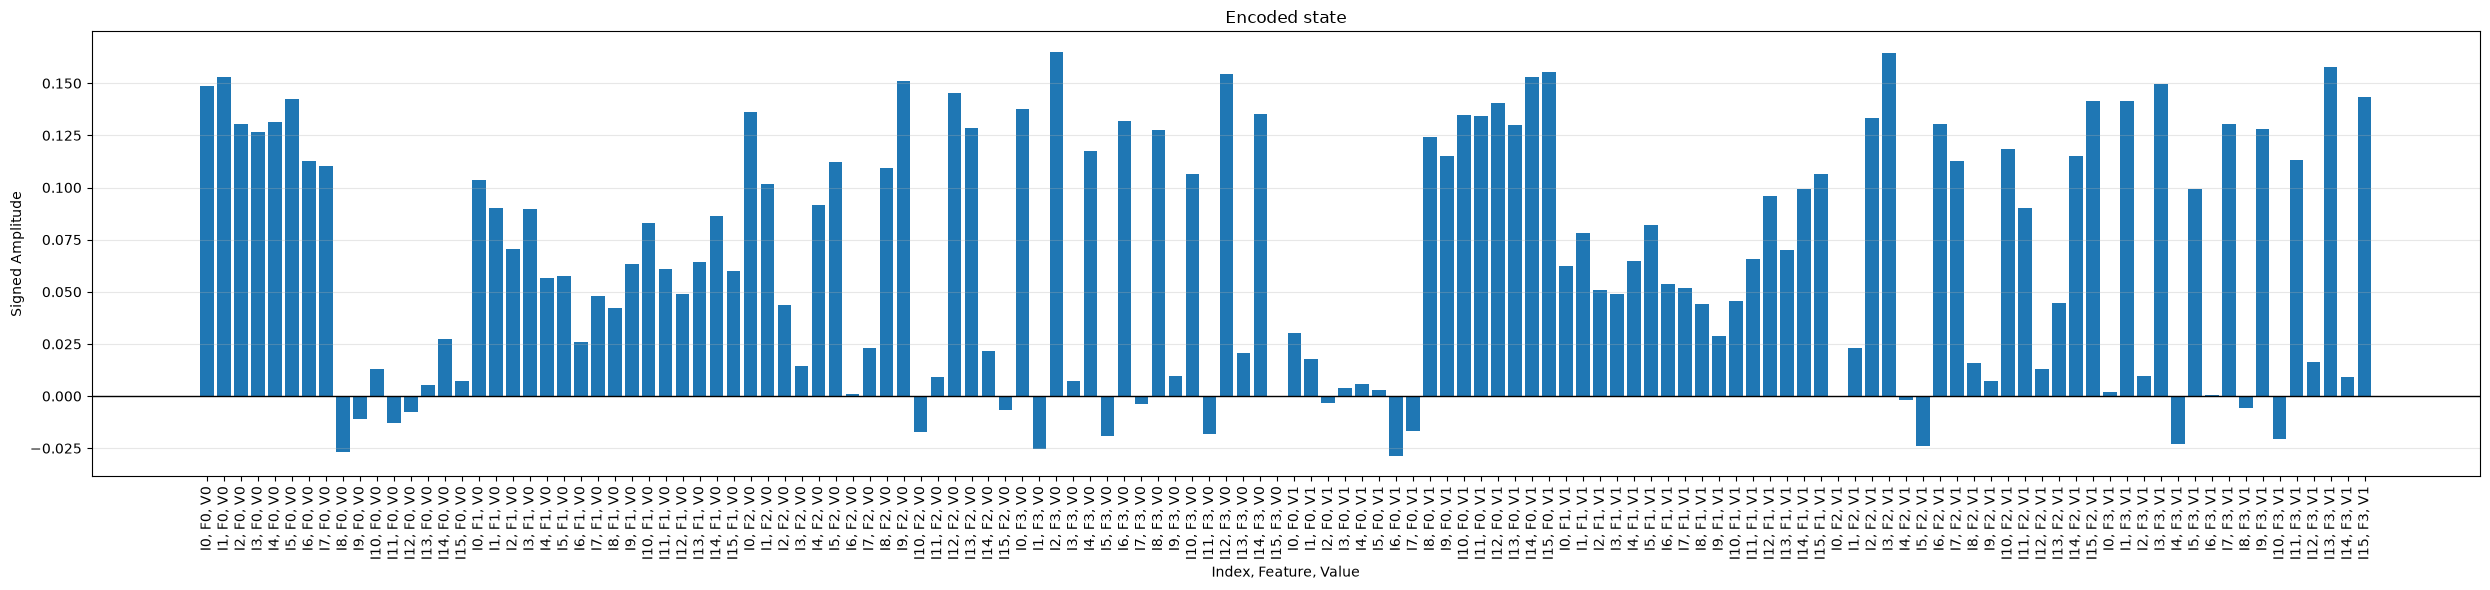


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


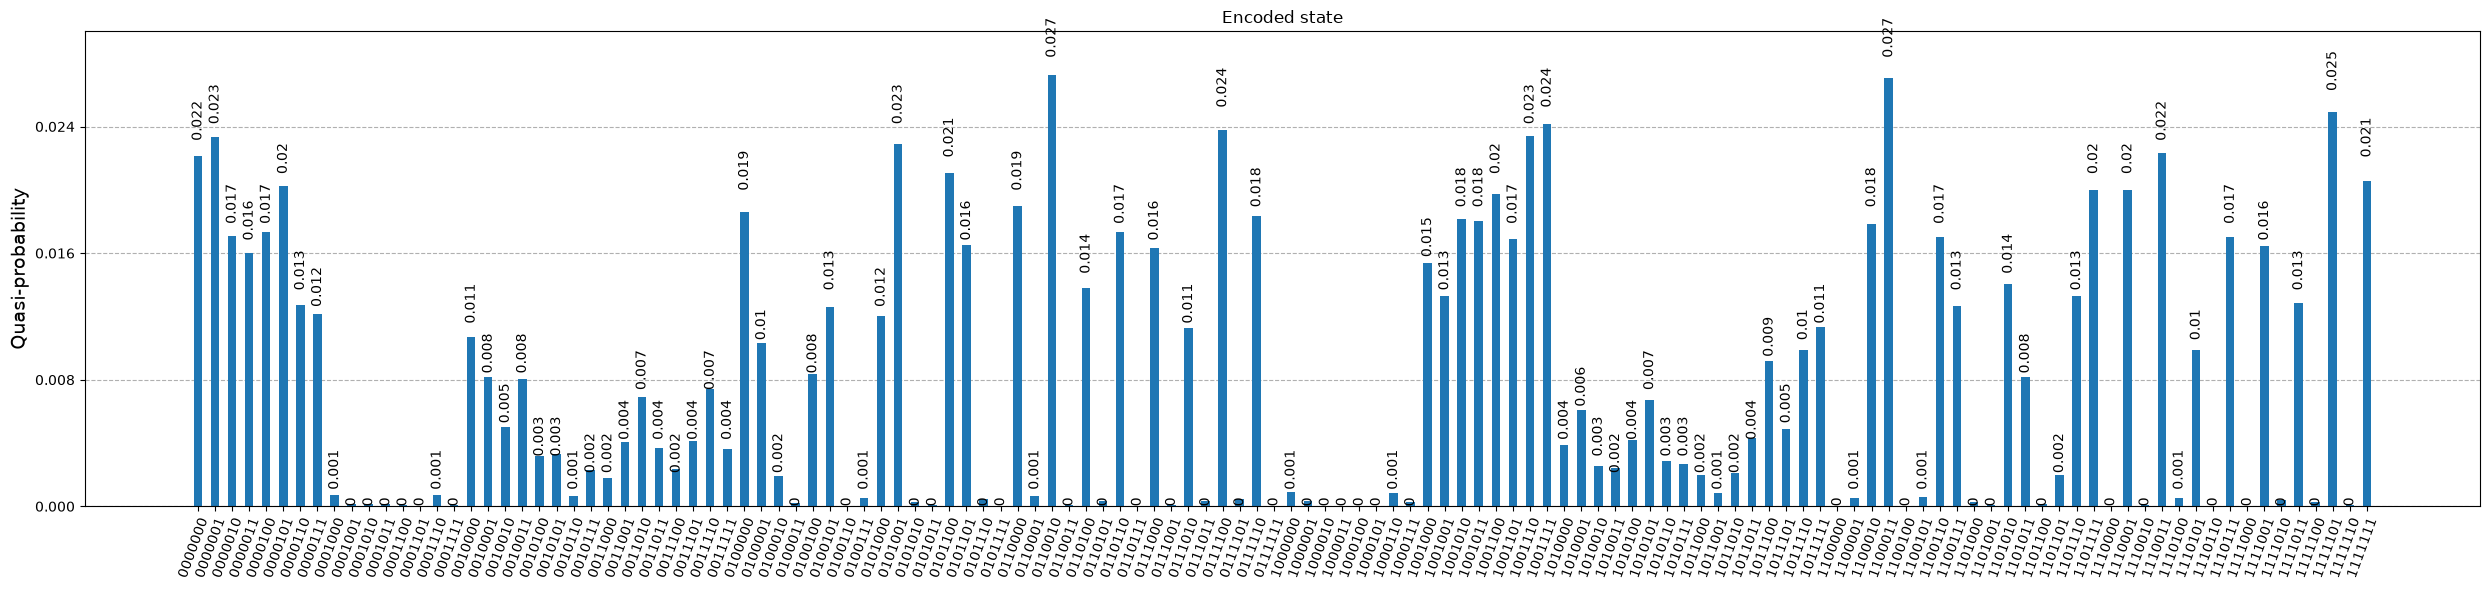

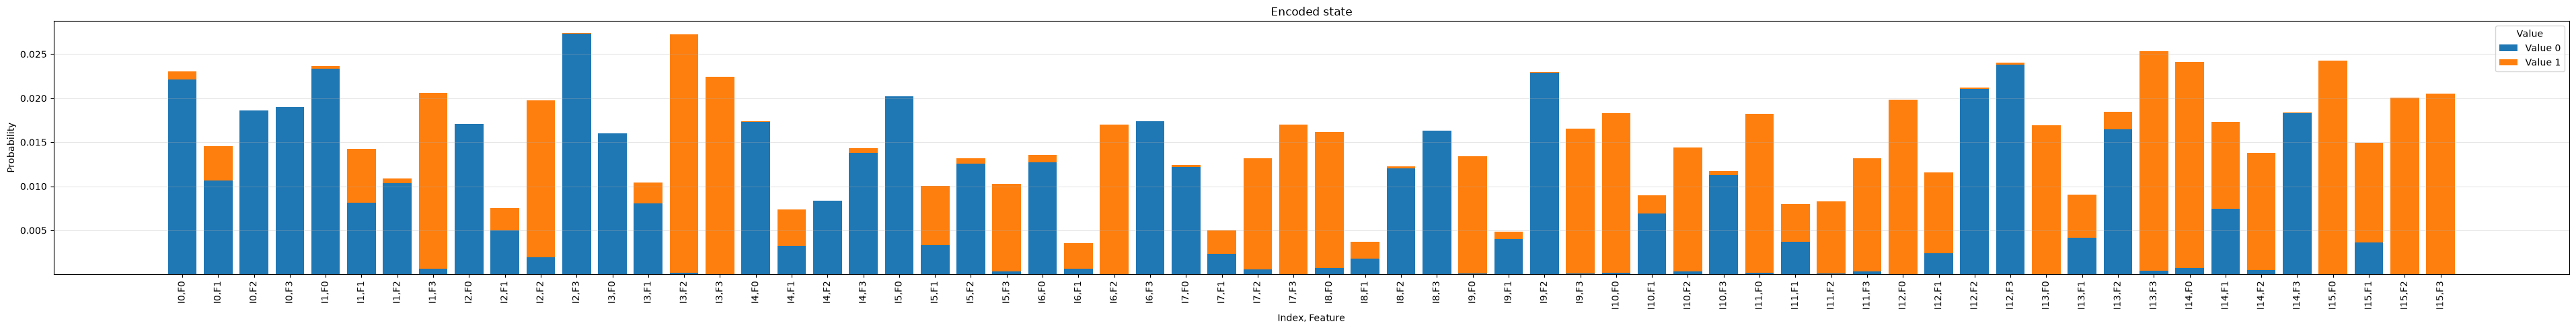


Encoded state
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.149                   +0.030                   
0                        1                        +0.103                   +0.062                   
0                        2                        +0.136                   -0.001                   
0                        3                        +0.138                   +0.002                   
1                        0                        +0.153                   +0.018                   
1                        1                        +0.090                   +0.078                   
1                        2                        +0.102                   +0.023                   
1                        3                        -0.025                   +

In [ ]:
A_parameters, A_best_fidelity = encoder.generate_encoding(dataset, scheme="NEQR", depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_encoder, learning_rate=learning_rate_dataset_encoder, loss_function_type="FIDELITY")

In [ ]:
if A_best_fidelity > A_saved_best_fidelity:
    save_parameters(
        A_parameters,
        depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_encoder, 
        learning_rate=learning_rate_dataset_encoder, fidelity=A_best_fidelity,
        scheme="NEQR", loss_function_type="FIDELITY"
    )

    print("New dataset encoder has better fidelity. Saved the new parameters.")

else:
    print(f"New dataset encoder did not improve fidelity {A_saved_best_fidelity}. Keeping the previous best parameters.")

print(f"Final best A fidelity = {A_best_fidelity:.6f}")

New dataset encoder did not improve fidelity 0.9851574558504578. Keeping the previous best parameters.
Final best A fidelity = 0.877243



> Preparing query target state....

Number of feature qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 3
Total number of states (total_num_states): 8

Amplitude =  0.5

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 4

> Starting training....

Number of parameters = 9

> Using adam optimization....
Epoch 1 - Loss 0.7536694199031233 - Fidelity 0.24633058009687672
Epoch 2 - Loss 0.6932617651335324 - Fidelity 0.3067382348664676
Epoch 3 - Loss 0.6475102697531232 - Fidelity 0.35248973024687674
Epoch 4 - Loss 0.6141819313074973 - Fidelity 0.3858180686925027
Epoch 5 - Loss 0.5849797508113557 - Fidelity 0.41502024918864433
Epoch 6 - Loss 0.547528900322604 - Fidelity 0.4524710996773959
Epoch 7 - Loss 0.4931303655314633 - Fidelity 0.5068696344685367
Epoch 8 - Loss 0.4227954041206021 - Fidelity 0.5772045958793979
Epoch 9 - Loss 0.3431288590683522 - Fidelity 0.6568711409316478
Epoch 10 - Loss 0.2627841478706394 - Fidelity 0.7372158521293606
Epoch 11 - Loss 0.1897502662187125 - Fidelity 0.8102497337812875
Epoch 12 - Loss 0.13036172488829634 - Fidelity 0.8696382751117037
Epoch 13 - Loss 0.08854555538848108 - Fidelity 0.9114544446115189
Epoch 14 - Loss 0.06504857924290552 - 

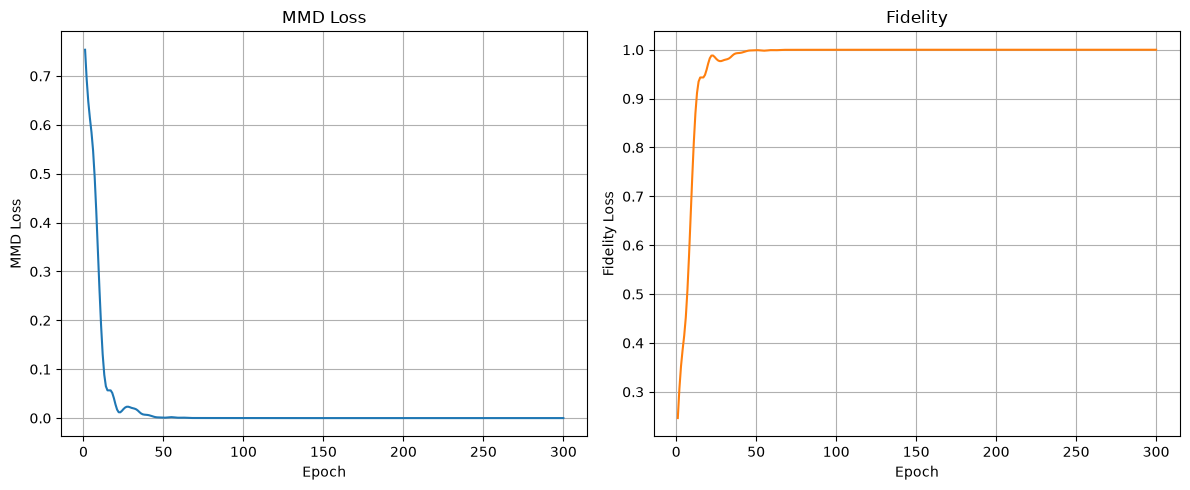


> Training finished.
Number of qubits: 3
Circuit depth (layers): 3
Number of parameters: 9
Best fidelity achieved: 0.99999951


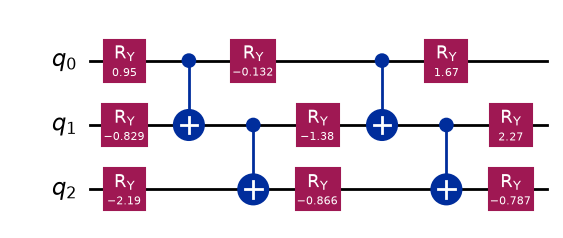


Data =  [1 0 1 1]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.99999951


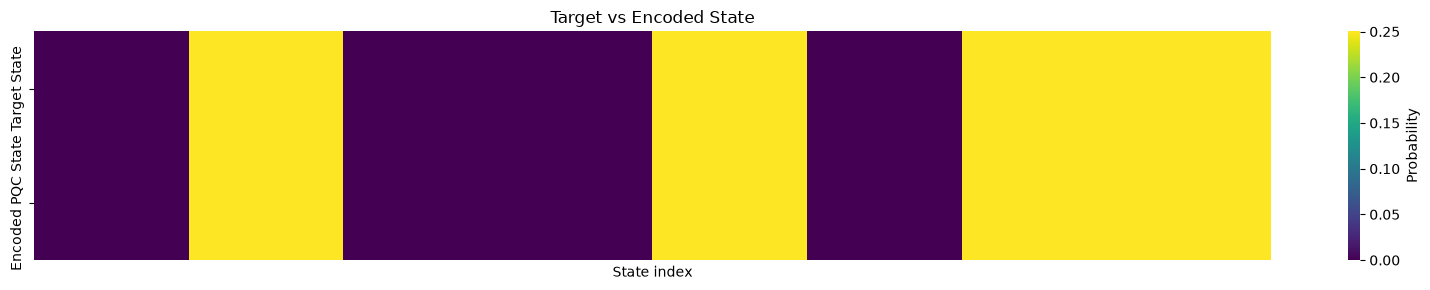

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

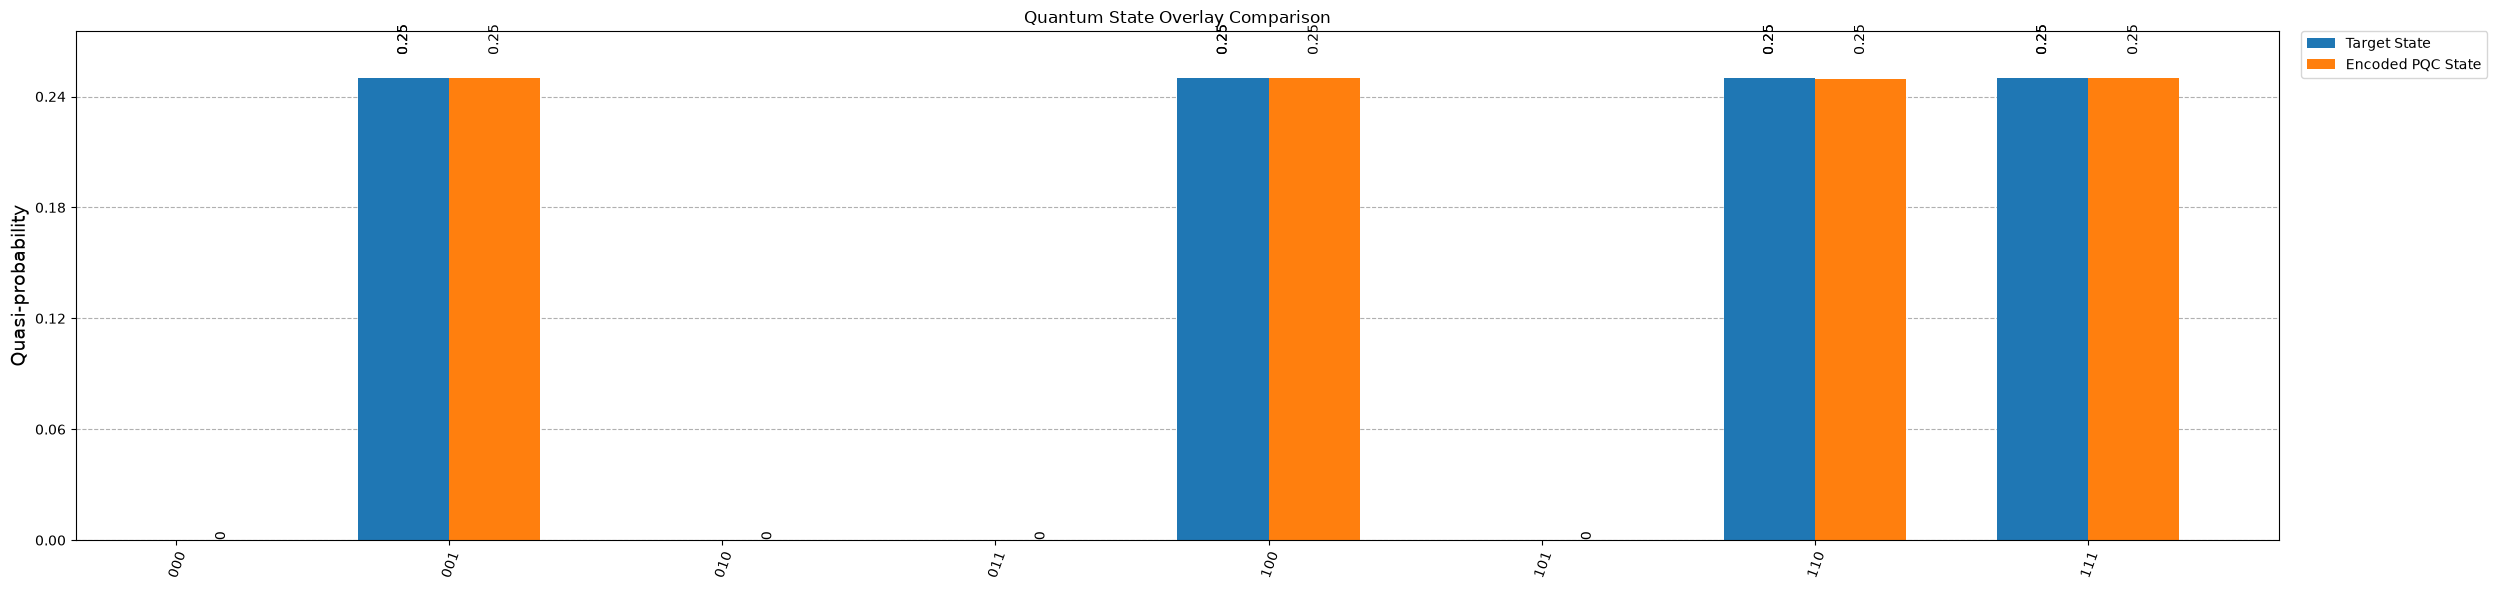


TARGET STATE
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.000                   +0.500                   
1                        +0.500                   +0.000                   
2                        +0.000                   +0.500                   
3                        +0.000                   +0.500                   

ENCODED STATE
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        -0.000                   -0.500                   
1                        -0.500                   +0.000                   
2                        +0.000                   -0.500                   
3                        -0.000                   -0.500                   

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000> : (-0.00027644834340165167+0j)
|001> : (-0.49993797774056126+0j)
|010> : (4.222619267825141e-05+0j)
|011> : (-0.00035465866188577074+0j)
|100> : (-0.5002438257239799+0j)
|110> : (-0.4995882699032875+0j)
|111> : (-0.5002294371767797+0j)


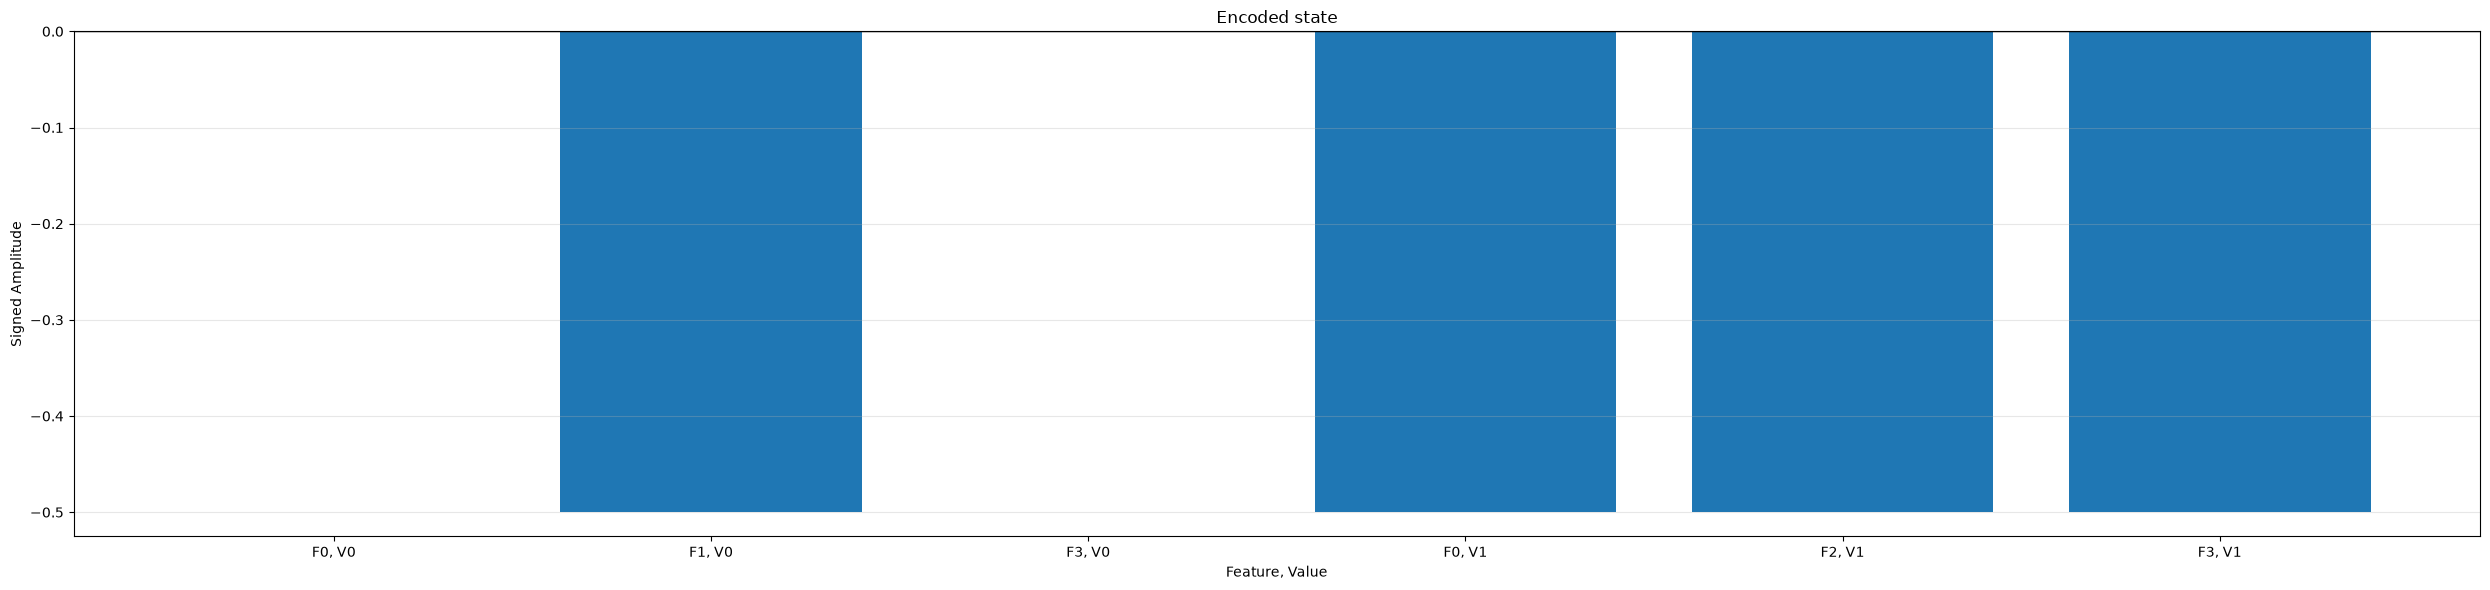


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


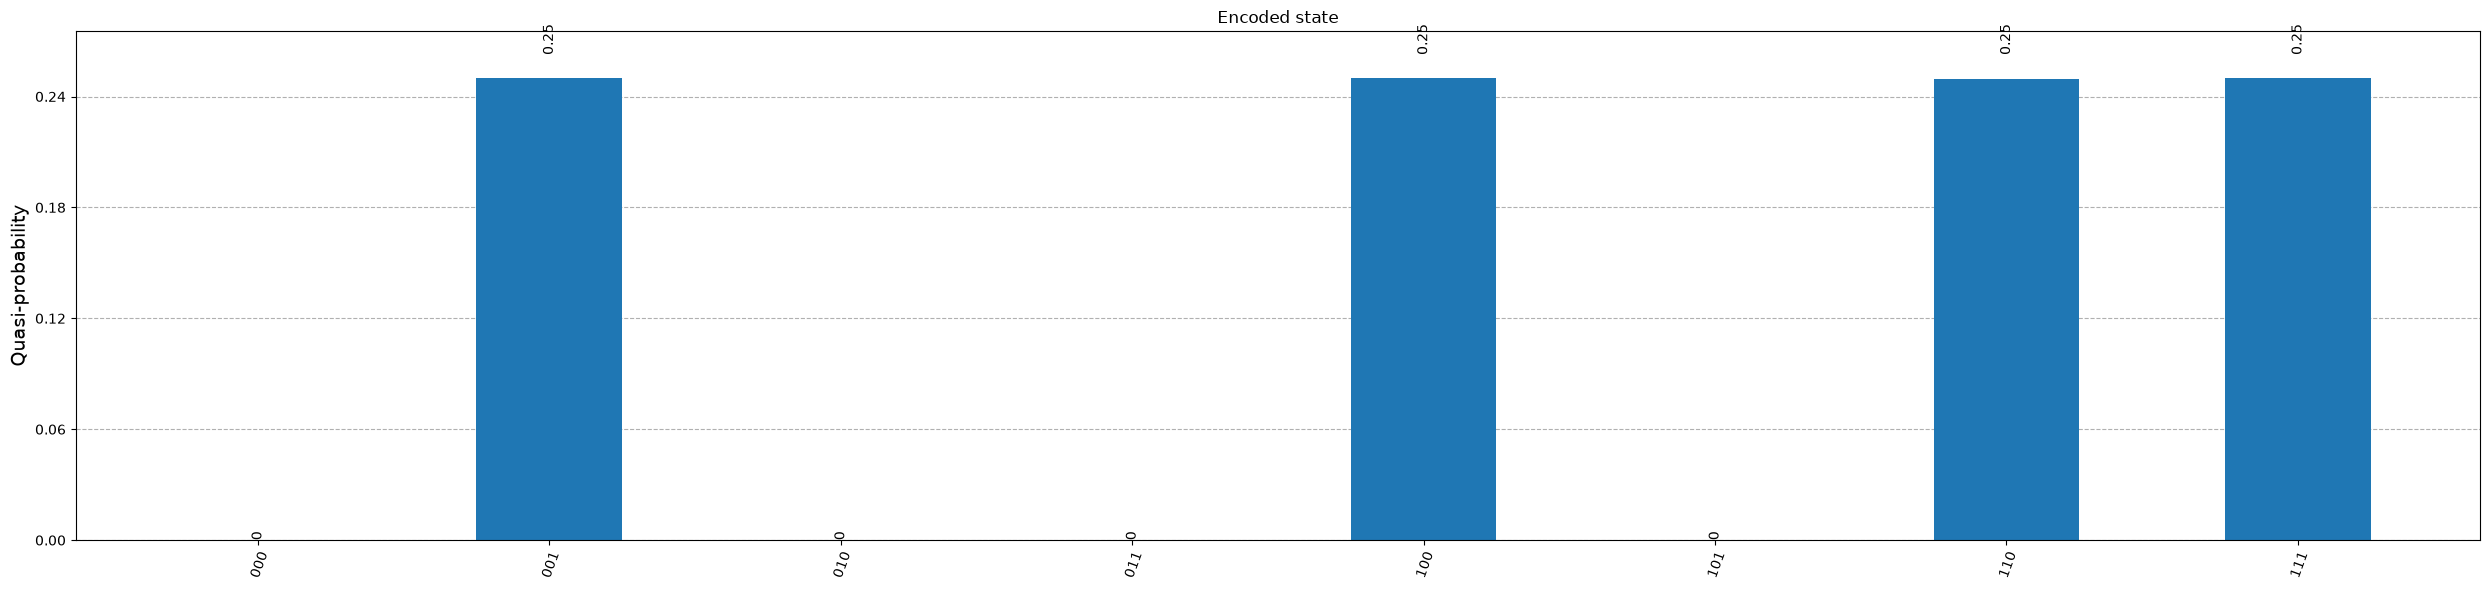

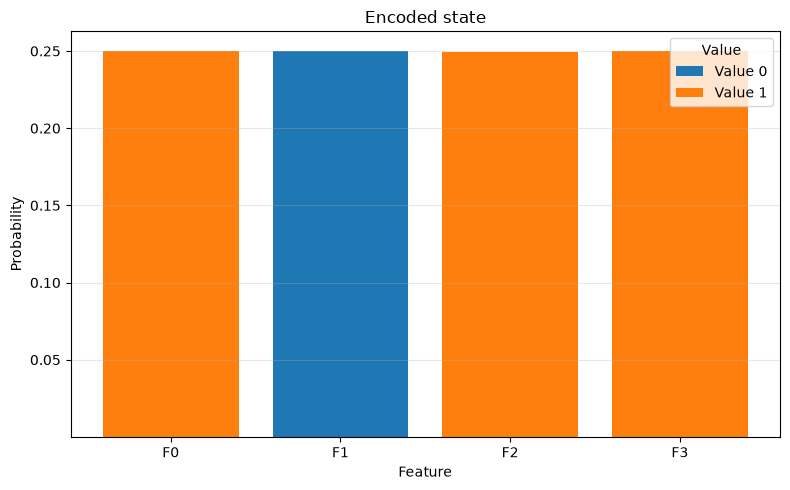


Encoded state
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        -0.000                   -0.500                   
1                        -0.500                   +0.000                   
2                        +0.000                   -0.500                   
3                        -0.000                   -0.500                   


In [ ]:
B_parameters_neqr_fidelity, _ = encoder.generate_encoding(query, scheme="NEQR", depth=pqc_depth_for_query_encoder, epochs=300, learning_rate=0.1, loss_function_type="FIDELITY")

## <u>**U operation**</u>

U = (B† ⊗ I_I) A

In [ ]:
n_index_q = math.ceil(math.log2(len(dataset)))
n_feature_q = math.ceil(math.log2(len(dataset[0])))

max_value = int(np.max(dataset))
n_value_q = max(1, math.ceil(math.log2(max_value + 1)))
print("Index qubits = ", n_index_q)
print("Feature qubits = ", n_feature_q)
print("Value qubits = ", n_value_q)

Index qubits =  4
Feature qubits =  2
Value qubits =  1


In [ ]:
A = encoder.pqc(
    A_parameters, depth=pqc_depth_for_dataset_encoder, n_qubits=(n_index_q + n_feature_q + n_value_q)
)

In [ ]:
B = encoder.pqc(
    B_parameters_neqr_fidelity, depth=pqc_depth_for_query_encoder, n_qubits=(n_value_q + n_feature_q)
)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (1+0j)


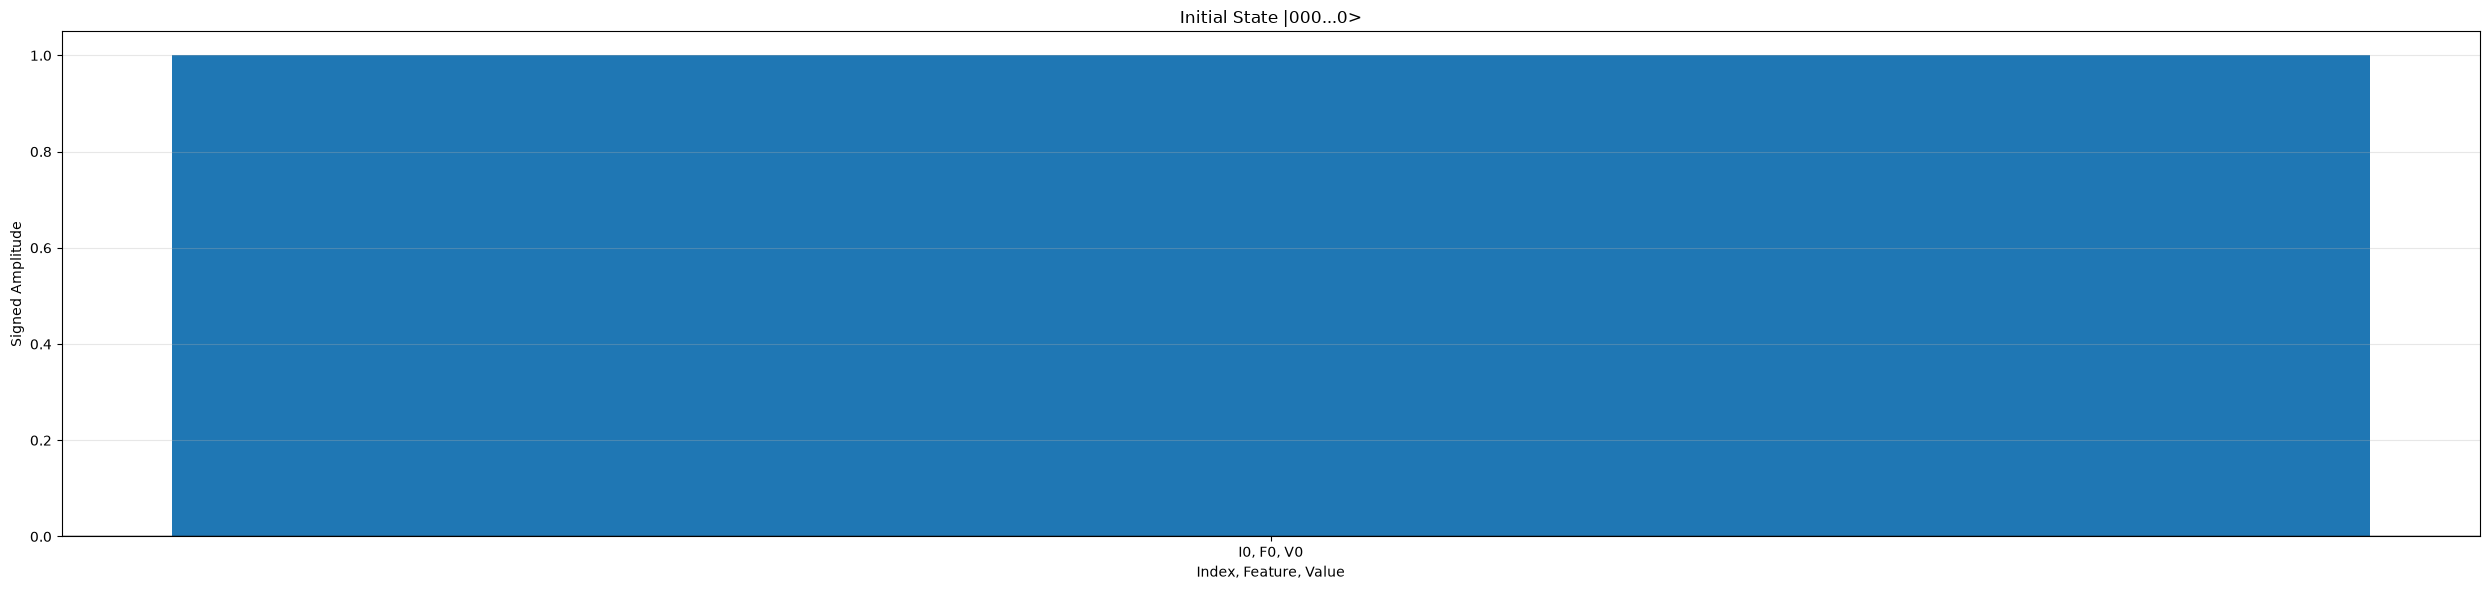


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


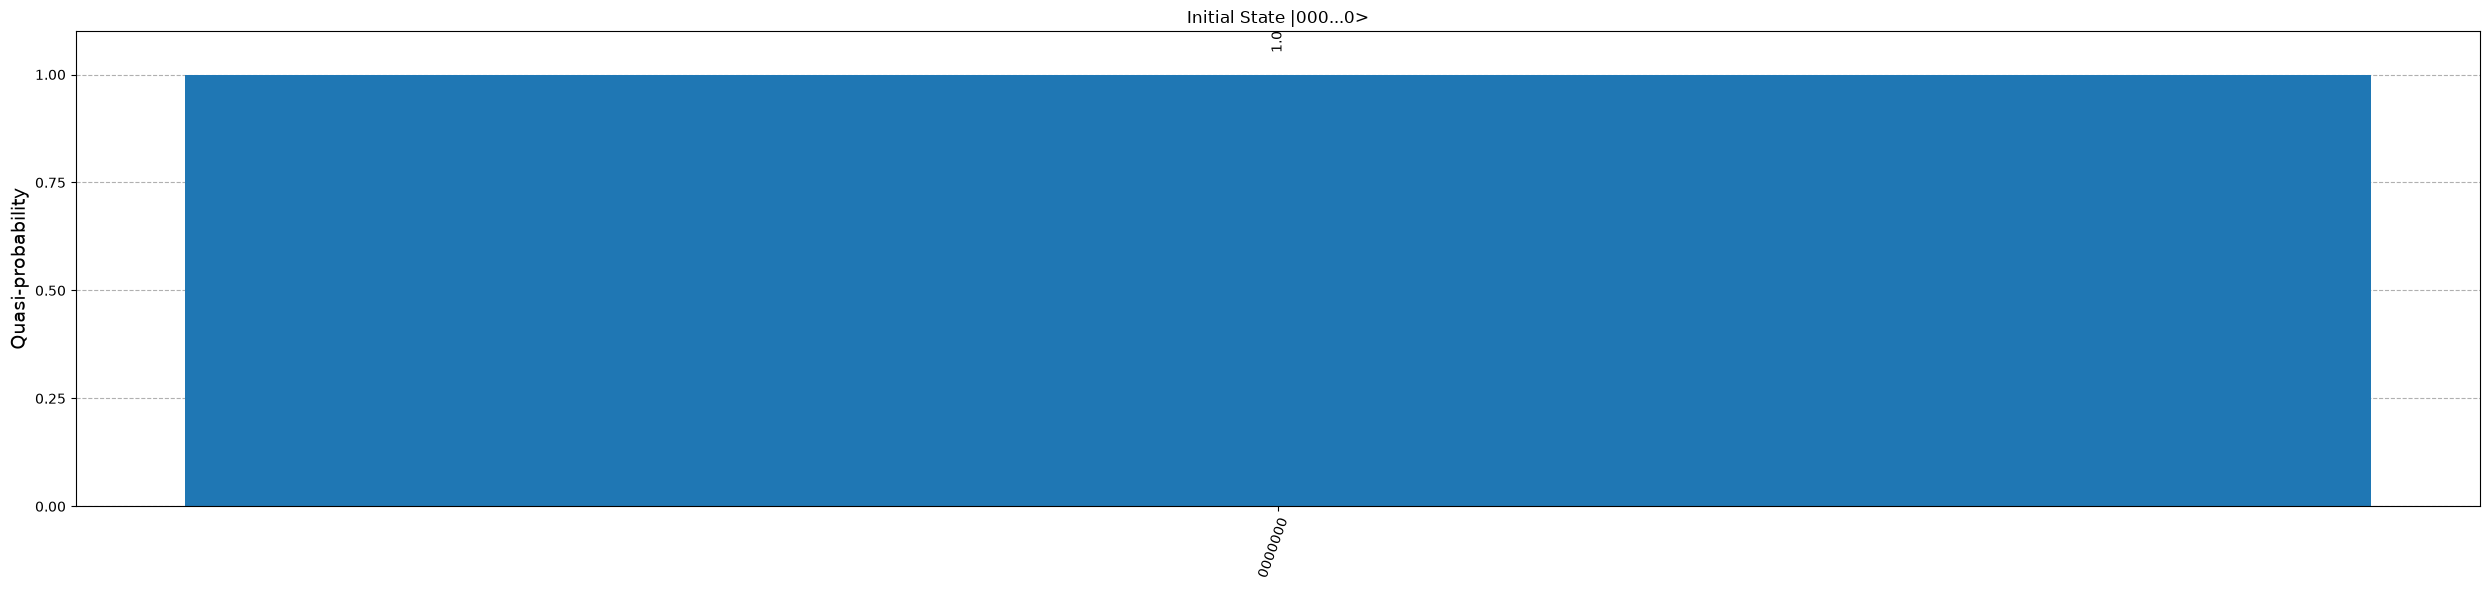

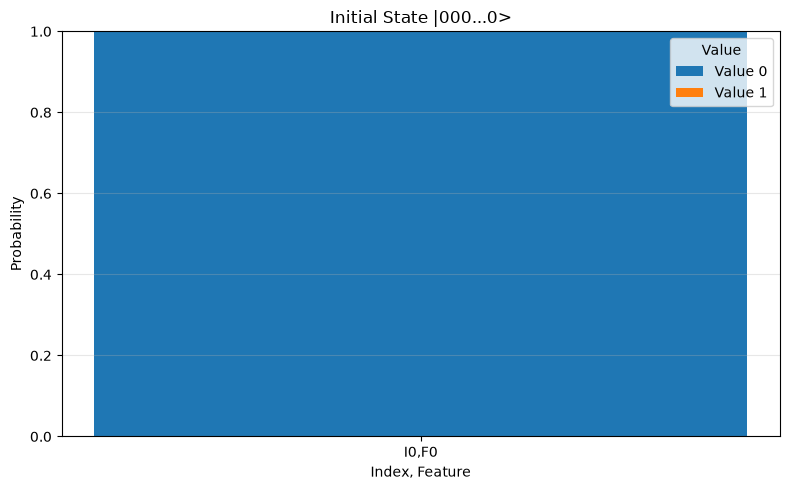


Initial State |000...0>
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +1.000                   +0.000                   


In [ ]:
value_reg = QuantumRegister(n_value_q)
feature_reg = QuantumRegister(n_feature_q)
index_reg = QuantumRegister(n_index_q)
qc = QuantumCircuit(value_reg, feature_reg, index_reg)

initial_state = Statevector.from_instruction(qc)
state_analysis(initial_state, "Initial State |000...0>", n_value_q, n_feature_q, n_index_q)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.148810232912073+0j)
|0000001> : (0.1528175204918282+0j)
|0000010> : (0.13068912795524973+0j)
|0000011> : (0.12661353670138573+0j)
|0000100> : (0.13163966143333977+0j)
|0000101> : (0.14226128714781516+0j)
|0000110> : (0.11278040741108904+0j)
|0000111> : (0.11027537579300825+0j)
|0001000> : (-0.02685874921244492+0j)
|0001001> : (-0.011100748982697063+0j)
|0001010> : (0.01309290445649661+0j)
|0001011> : (-0.012729345875892353+0j)
|0001100> : (-0.007401878301207264+0j)
|0001101> : (0.005455697387470002+0j)
|0001110> : (0.02731272989136348+0j)
|0001111> : (0.0074303447939270285+0j)
|0010000> : (0.10340345918962107+0j)
|0010001> : (0.09034563275198197+0j)
|0010010> : (0.0706126619853581+0j)
|0010011> : (0.08955617956244892+0j)
|0010100> : (0.056607579028076505+0j)
|0010101> : (0.05764018411097157+0j)
|0010110> : (0.02588651488752697+0j)
|0010111> : (0.04817603343076083+0j)
|0011000> : (0.04208878279004878+0j)
|0011001> : (0.06354127992283266+0j)
|

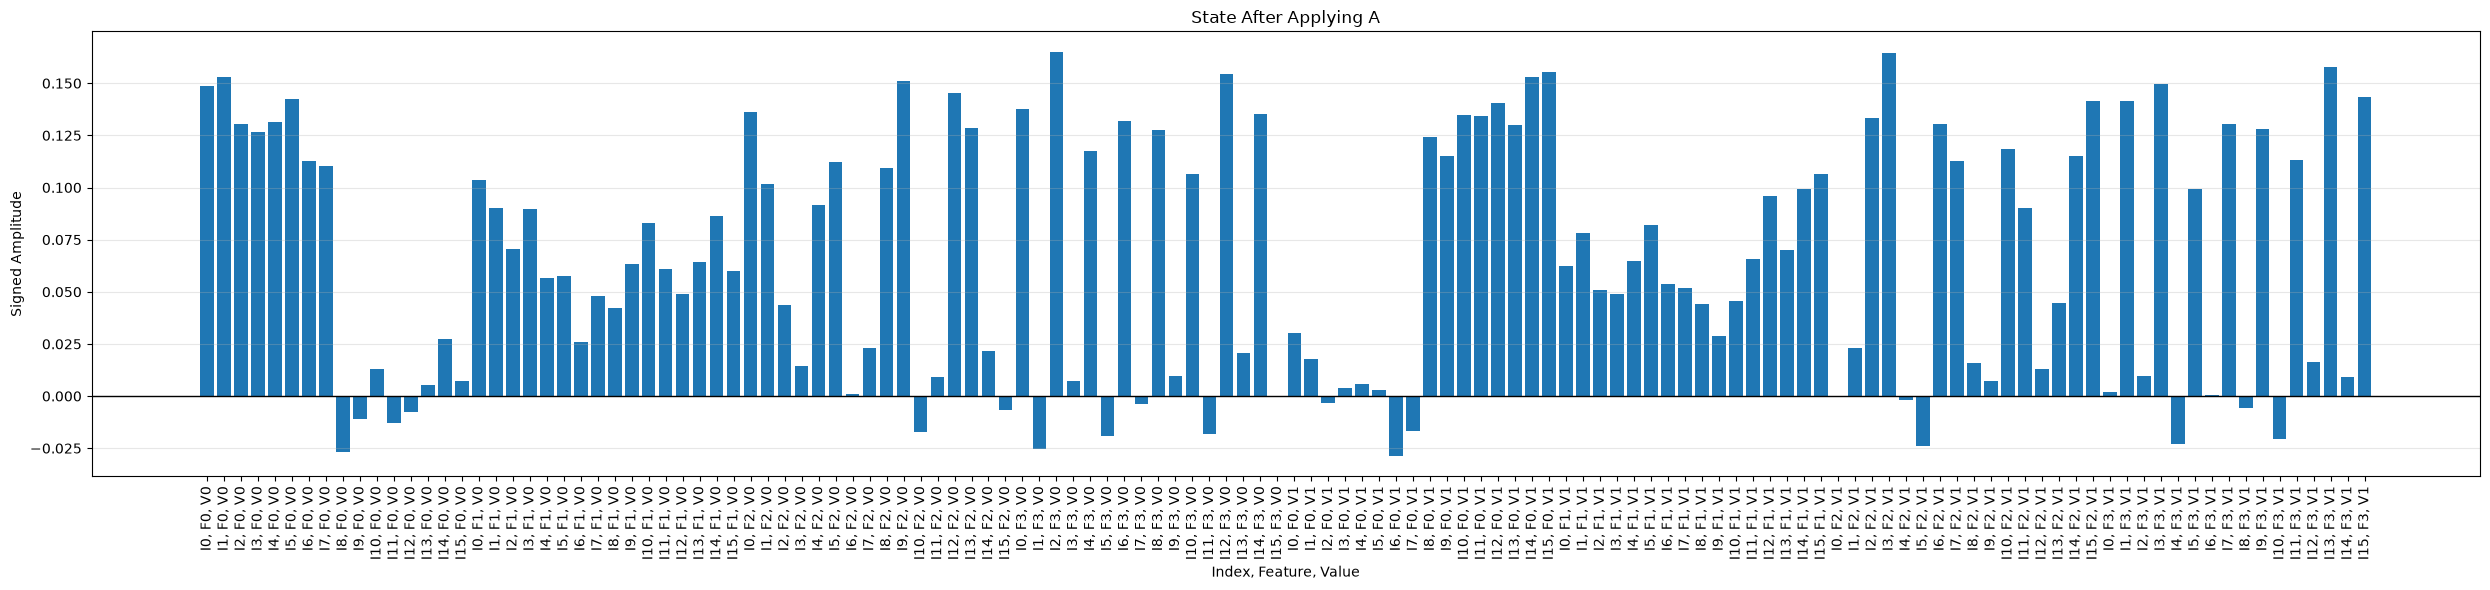


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


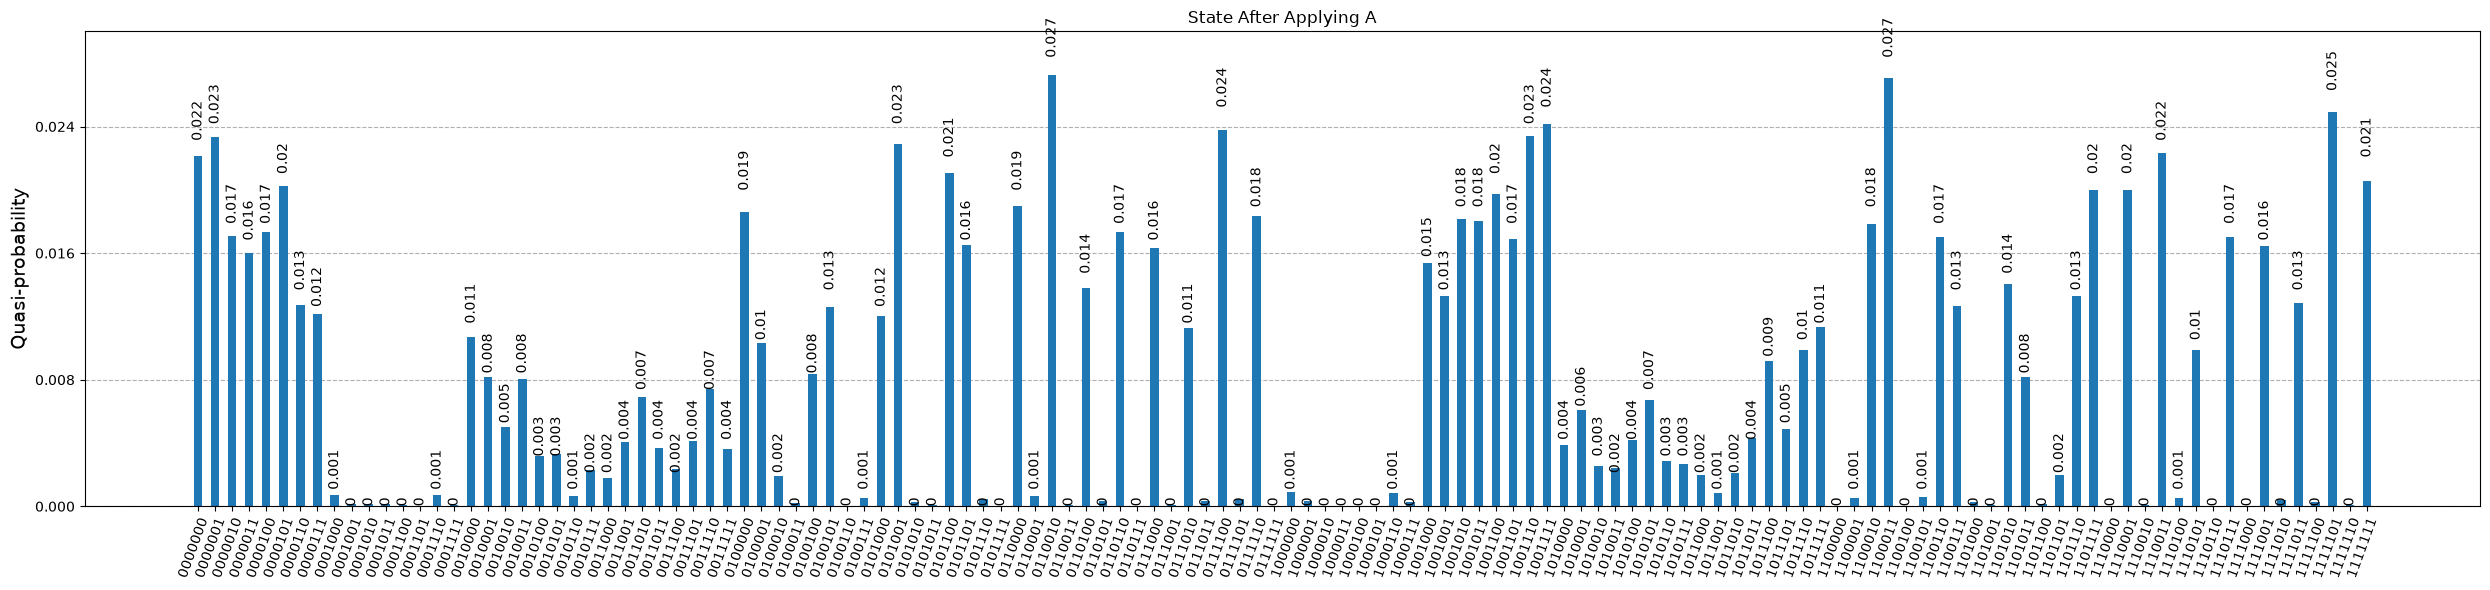

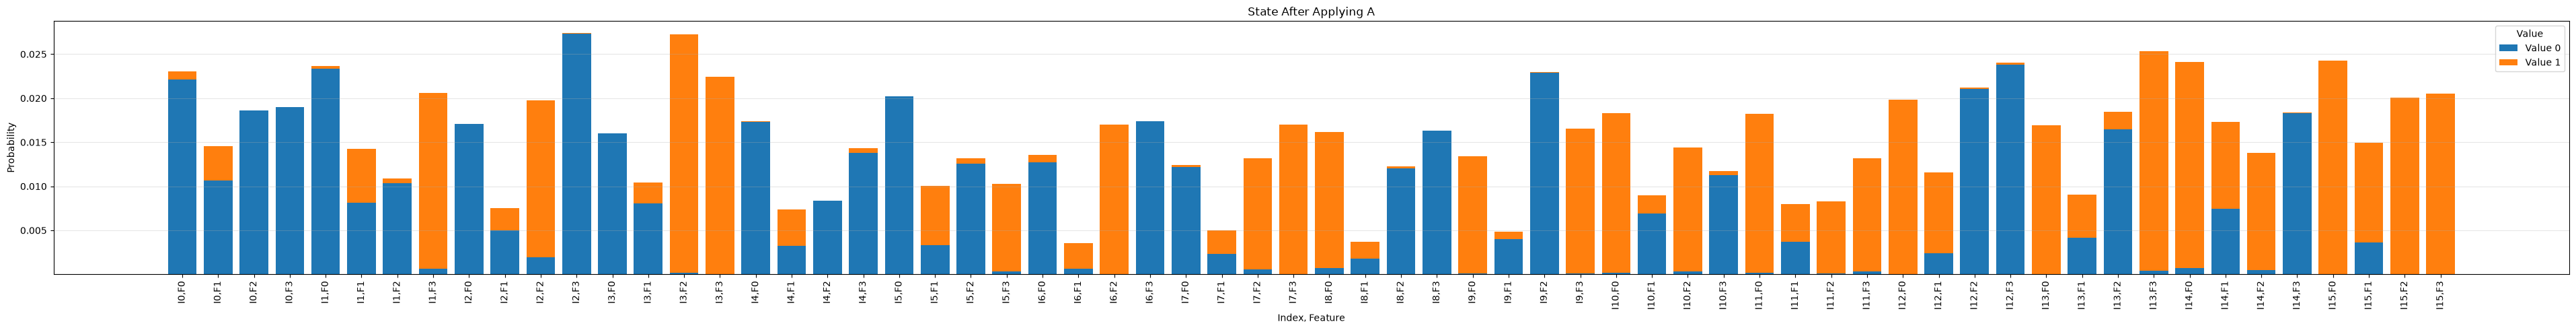


State After Applying A
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.149                   +0.030                   
0                        1                        +0.103                   +0.062                   
0                        2                        +0.136                   -0.001                   
0                        3                        +0.138                   +0.002                   
1                        0                        +0.153                   +0.018                   
1                        1                        +0.090                   +0.078                   
1                        2                        +0.102                   +0.023                   
1                        3                        -0.025           

In [ ]:
qc.compose(A, inplace=True)
qc.barrier()

state_after_A = Statevector.from_instruction(qc)

state_analysis(state_after_A, "State After Applying A", n_value_q, n_feature_q, n_index_q)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.25383817245446866+0j)
|0000001> : (0.14939846691129674+0j)
|0000010> : (-0.005683770129576695+0j)
|0000011> : (-0.023305510548173692+0j)
|0000100> : (0.14454009763685371+0j)
|0000101> : (-0.09019253756960048+0j)
|0000110> : (0.1460213649769915+0j)
|0000111> : (-0.05811819381711982+0j)
|0001000> : (-0.008097061994305363+0j)
|0001001> : (0.0023513988401123987+0j)
|0001010> : (0.012700948095737357+0j)
|0001011> : (-0.0073820833041919115+0j)
|0001100> : (-0.03522873698382605+0j)
|0001101> : (-0.0008248501914362923+0j)
|0001110> : (-0.004772470540083478+0j)
|0001111> : (-0.022636378172274724+0j)
|0010000> : (-0.11057371043442589+0j)
|0010001> : (0.07308715696970192+0j)
|0010010> : (-0.02738329891611997+0j)
|0010011> : (0.00671998444002627+0j)
|0010100> : (0.10483909280787061+0j)
|0010101> : (-0.046103882840400685+0j)
|0010110> : (0.09777287333985003+0j)
|0010111> : (-0.018420026593446596+0j)
|0011000> : (-0.12943848837952543+0j)
|0011001> : (0.0

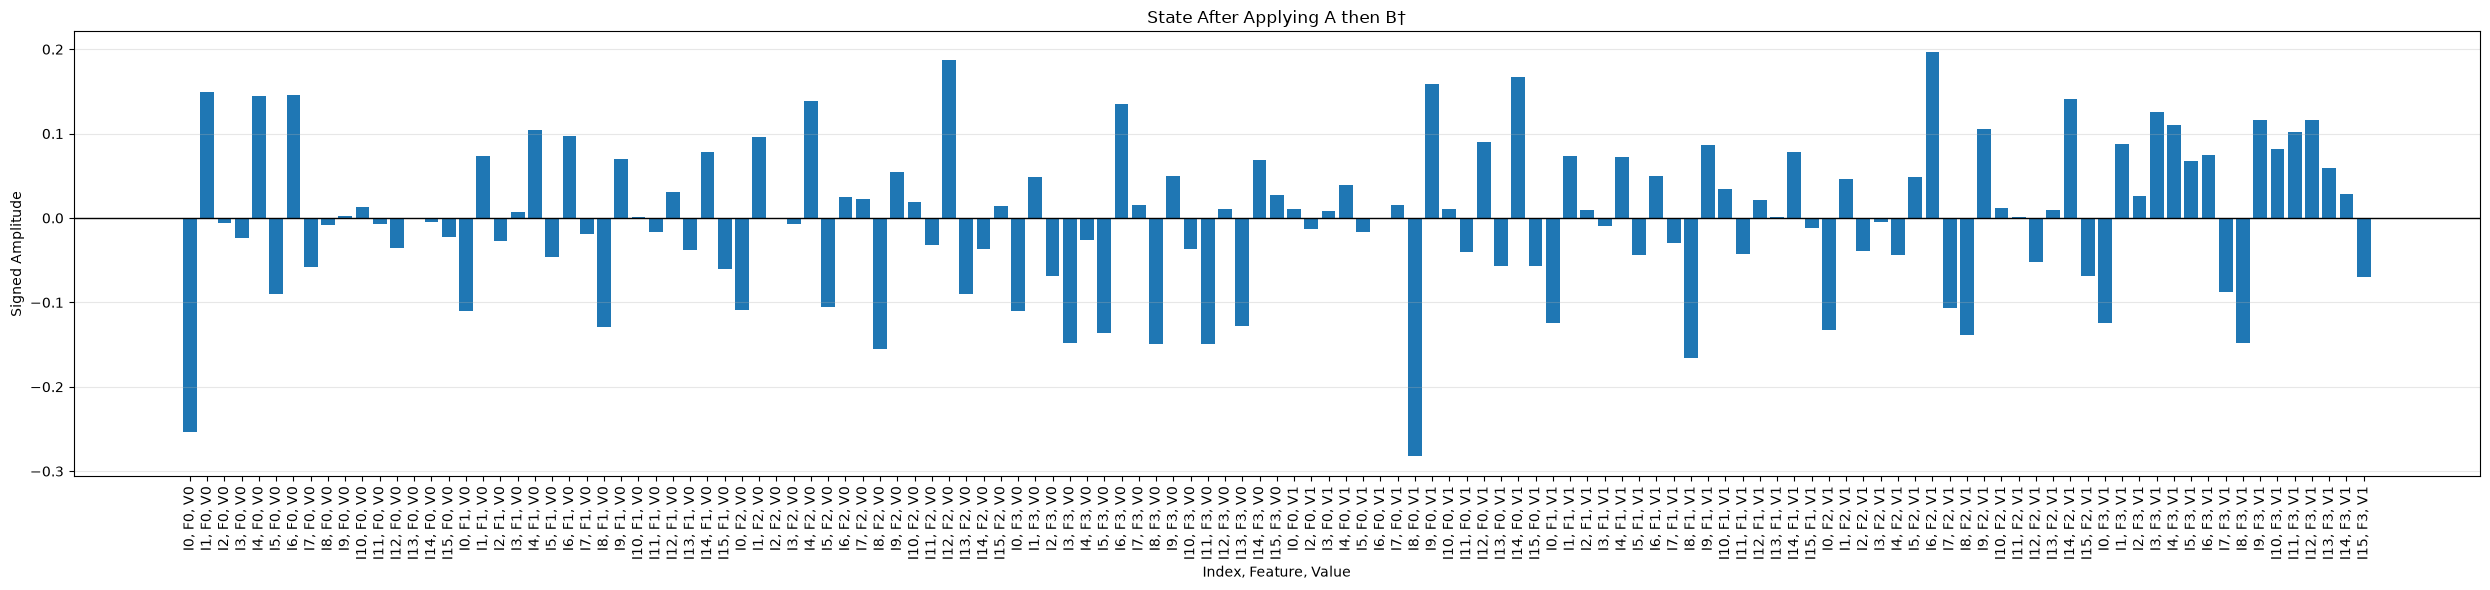


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


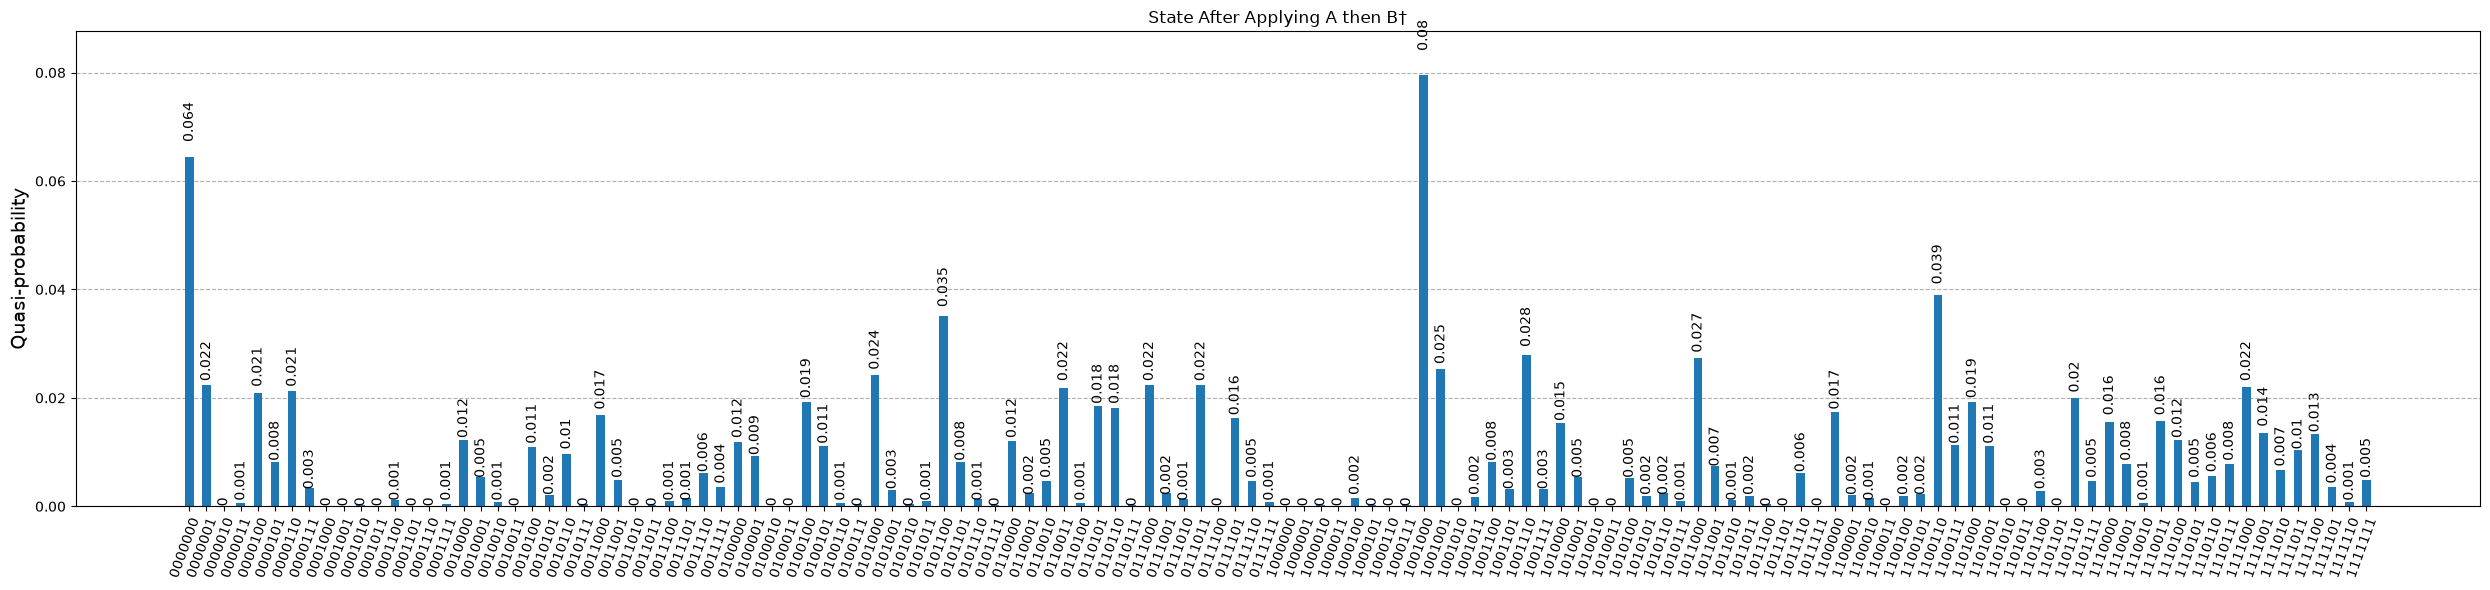

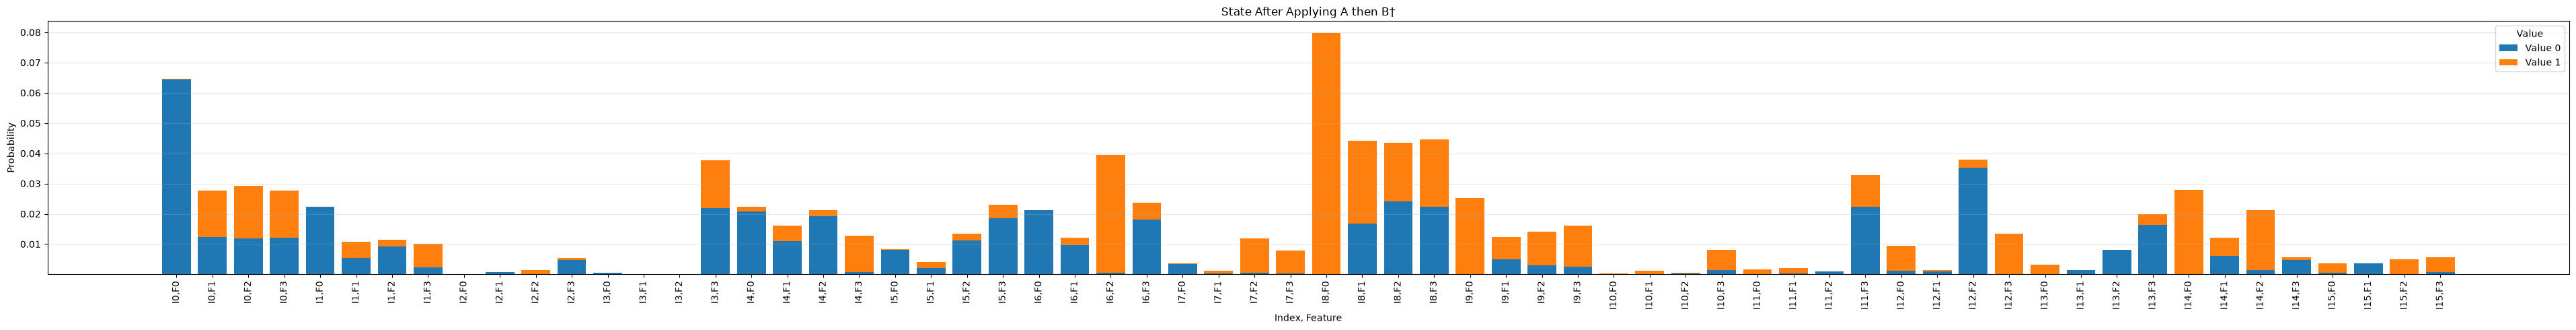


State After Applying A then B†
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.254                   +0.011                   
0                        1                        -0.111                   -0.124                   
0                        2                        -0.109                   -0.132                   
0                        3                        -0.110                   -0.125                   
1                        0                        +0.149                   +0.000                   
1                        1                        +0.073                   +0.074                   
1                        2                        +0.096                   +0.047                   
1                        3                        +0.049   

In [ ]:
qc.compose(B.inverse(), qubits=range(n_feature_q + n_value_q), inplace=True)
qc.barrier()

state_after_B_inverse = Statevector.from_instruction(qc)

state_analysis(state_after_B_inverse, "State After Applying A then B†", n_value_q, n_feature_q, n_index_q)

For query index = 0
Total probability for index 0 =  (-0.250)^2+(+0.000)^2+(-0.249)^2+(-0.000)^2+(-0.125)^2+(-0.126)^2+(-0.124)^2+(-0.126)^2

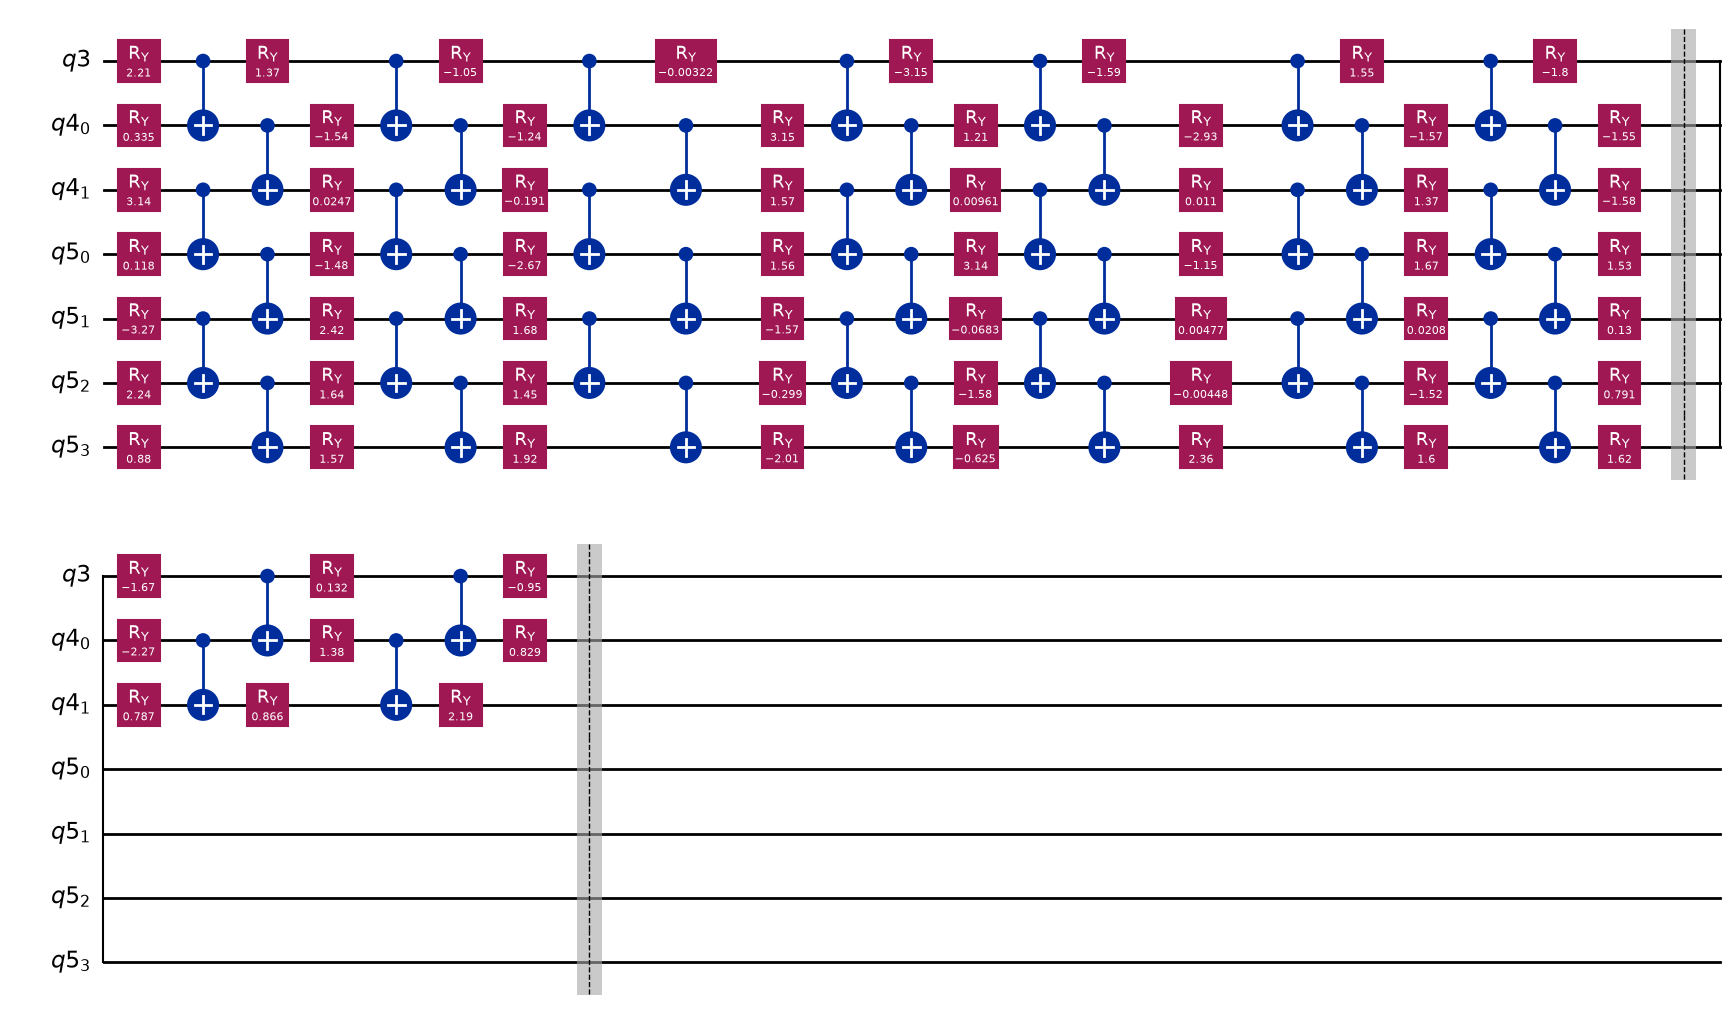

In [ ]:
display(qc.draw("mpl"))

# <u>**Part 2: Use Grover Search for Image Matching**</u>

In [ ]:
try:
    A_saved = load_parameters(scheme="NEQR", loss_function_type="FIDELITY")

    A_saved_parameters = A_saved["parameters"]
    A_saved_best_fidelity = A_saved["fidelity"]

    print(f"Loaded saved A. Fidelity = {A_saved_best_fidelity:.6f}")

except (ValueError, KeyError, OSError) as e:
    print(f"Could not reuse saved dataset enocder. Train again.")

NameError: name 'ENCODING_FILE' is not defined

In [ ]:
A_parameters

In [ ]:
A_parameters = A_parameters['parameters']

In [ ]:
GS = GroverSearch()

## <u>**GS with NEQR scheme and MMD cost function**</u>

In [ ]:
# GS.run(dataset=dataset, query=query,
#     A_parameters=A_parameters_neqr_mmd, B_parameters=B_parameters_neqr_mmd,
#     depth_A=6, depth_B=3,
#     num_of_iter=5
# )

In [ ]:
query_index

In [ ]:
# GS.draw_circuit()

In [ ]:
# GS.analysis()

## <u>**GS with NEQR scheme and FIDELITY cost function**</u>

In [ ]:
GS.run(dataset=dataset, query=query,
    A_parameters=A_parameters, B_parameters=B_parameters_neqr_fidelity,
    depth_A=pqc_depth_for_dataset_encoder, depth_B=pqc_depth_for_query_encoder,
    num_of_iter=5
)

In [ ]:
GS.draw_circuit()

In [ ]:
GS.analysis()